# ⚙️ ChurnShield AI — Feature Engineering

**Objetivo:** Criar e validar as features derivadas que alimentam os modelos de ML.

**Etapas:**
1. Criação de features numéricas derivadas
2. Encoding de variáveis categóricas
3. Tratamento de outliers
4. Balanceamento de classes com SMOTE
5. Seleção de features por importância

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

from src.data.data_loader import ChurnDataLoader
from src.features.feature_engineering import (
    build_feature_pipeline,
    apply_smote,
    get_feature_importance_ranking
)

with open('../config/config.yaml') as f:
    CONFIG = yaml.safe_load(f)

sns.set_theme(style='whitegrid')
print('✅ Pronto!')

✅ Pronto!


## 1. Carregamento e Split

In [2]:
loader = ChurnDataLoader(CONFIG)
df = loader.load(use_synthetic=True)
X_train, X_test, y_train, y_test = loader.get_splits(df)

print(f'Treino: {X_train.shape} | Teste: {X_test.shape}')
print(f'Features originais: {X_train.columns.tolist()}')

2026-04-26 00:58:30.575 | INFO     | src.data.data_loader:load:267 - Arquivo não encontrado. Usando dataset sintético...
2026-04-26 00:58:30.576 | INFO     | src.data.data_loader:generate_synthetic_dataset:50 - Gerando dataset sintético com 7,043 amostras...
2026-04-26 00:58:30.608 | SUCCESS  | src.data.data_loader:generate_synthetic_dataset:158 - Dataset gerado: 7,043 linhas | 21 colunas | Churn rate: 22.1%
2026-04-26 00:58:30.640 | INFO     | src.data.data_loader:load:271 - Dataset salvo em: data\raw\churn_data.csv
2026-04-26 00:58:30.650 | INFO     | src.data.data_loader:load:280 - Data hash: becc0750
2026-04-26 00:58:30.655 | SUCCESS  | src.data.data_loader:validate:226 - ✅ Validação de dados: PASSOU em todas as verificações
2026-04-26 00:58:30.661 | INFO     | src.data.data_loader:get_splits:330 - Split: train=5,634 | test=1,409 | churn_train=22.0% | churn_test=22.1%


Treino: (5634, 19) | Teste: (1409, 19)
Features originais: ['gender', 'senior_citizen', 'partner', 'dependents', 'tenure', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract_type', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges']


## 2. Pipeline de Feature Engineering

In [3]:
pipeline = build_feature_pipeline(CONFIG)

X_train_fe = pipeline.fit_transform(X_train, y_train)
X_test_fe = pipeline.transform(X_test)

print(f'Features originais: {X_train.shape[1]}')
print(f'Features após engineering: {X_train_fe.shape[1]}')
print(f'Novas features criadas: {X_train_fe.shape[1] - X_train.shape[1]}')

2026-04-26 00:58:32.902 | INFO     | src.features.feature_engineering:build_feature_pipeline:271 - Pipeline de features construído com 5 etapas
2026-04-26 00:58:32.907 | DEBUG    | src.features.feature_engineering:transform:76 - NumericalFeatureCreator: 26 features após transformação
2026-04-26 00:58:32.928 | DEBUG    | src.features.feature_engineering:transform:181 - CategoricalEncoder: 28 features após encoding
2026-04-26 00:58:32.936 | DEBUG    | src.features.feature_engineering:transform:233 - Outliers: 50 valores clipados em 'monthly_charges'
2026-04-26 00:58:32.946 | DEBUG    | src.features.feature_engineering:transform:76 - NumericalFeatureCreator: 26 features após transformação
2026-04-26 00:58:32.958 | DEBUG    | src.features.feature_engineering:transform:181 - CategoricalEncoder: 28 features após encoding
2026-04-26 00:58:32.963 | DEBUG    | src.features.feature_engineering:transform:233 - Outliers: 14 valores clipados em 'monthly_charges'


Features originais: 19
Features após engineering: 32
Novas features criadas: 13


In [4]:
# Verificar valores nulos e infinitos após transformação
print(f'NaN no treino: {np.isnan(X_train_fe).sum()}')
print(f'Inf no treino: {np.isinf(X_train_fe).sum()}')
print('✅ Dados limpos!')

NaN no treino: 0
Inf no treino: 0
✅ Dados limpos!


## 3. Balanceamento com SMOTE

c:\Users\kaiow\Desktop\git\ChurnShield\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] O sistema não pode encontrar o arquivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\kaiow\Desktop\git\ChurnShield\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\kaiow\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\kaiow\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\U

Antes do SMOTE:
churn
0    4392
1    1242
Name: count, dtype: int64

Depois do SMOTE:
churn
0    4392
1    4392
Name: count, dtype: int64


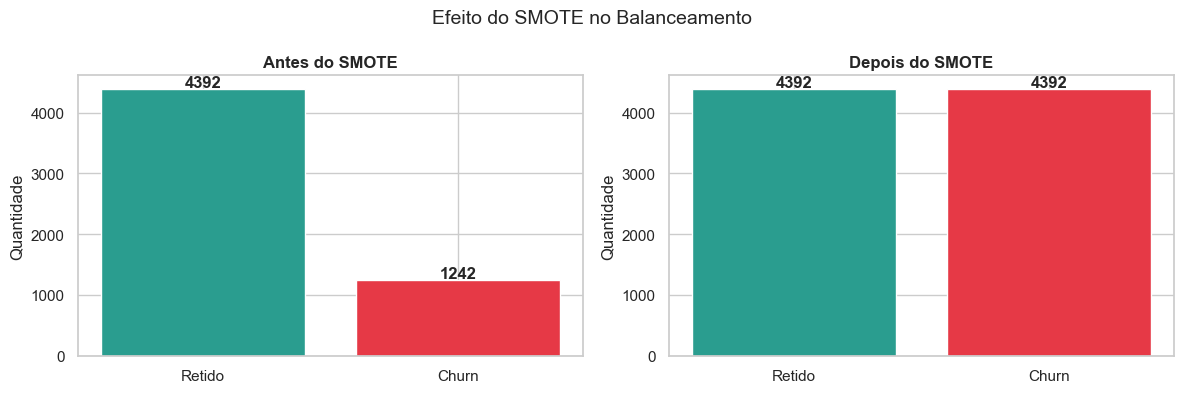

In [5]:
print('Antes do SMOTE:')
print(y_train.value_counts())

X_train_res, y_train_res = apply_smote(X_train_fe, y_train)

print('\nDepois do SMOTE:')
print(pd.Series(y_train_res).value_counts())

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (data, title) in zip(axes, [
    (y_train, 'Antes do SMOTE'),
    (pd.Series(y_train_res), 'Depois do SMOTE')
]):
    counts = pd.Series(data).value_counts()
    ax.bar(['Retido', 'Churn'], counts.values, color=['#2A9D8F', '#E63946'], edgecolor='white')
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Quantidade')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 30, str(v), ha='center', fontweight='bold')

plt.suptitle('Efeito do SMOTE no Balanceamento', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Importância de Features (Mutual Information)

2026-04-26 00:58:40.347 | INFO     | src.features.feature_engineering:get_feature_importance_ranking:320 - Top 5 features por Mutual Information:
    feature  mutual_info_score
28       28           0.050606
22       22           0.048337
31       31           0.037876
21       21           0.019237
6         6           0.018120


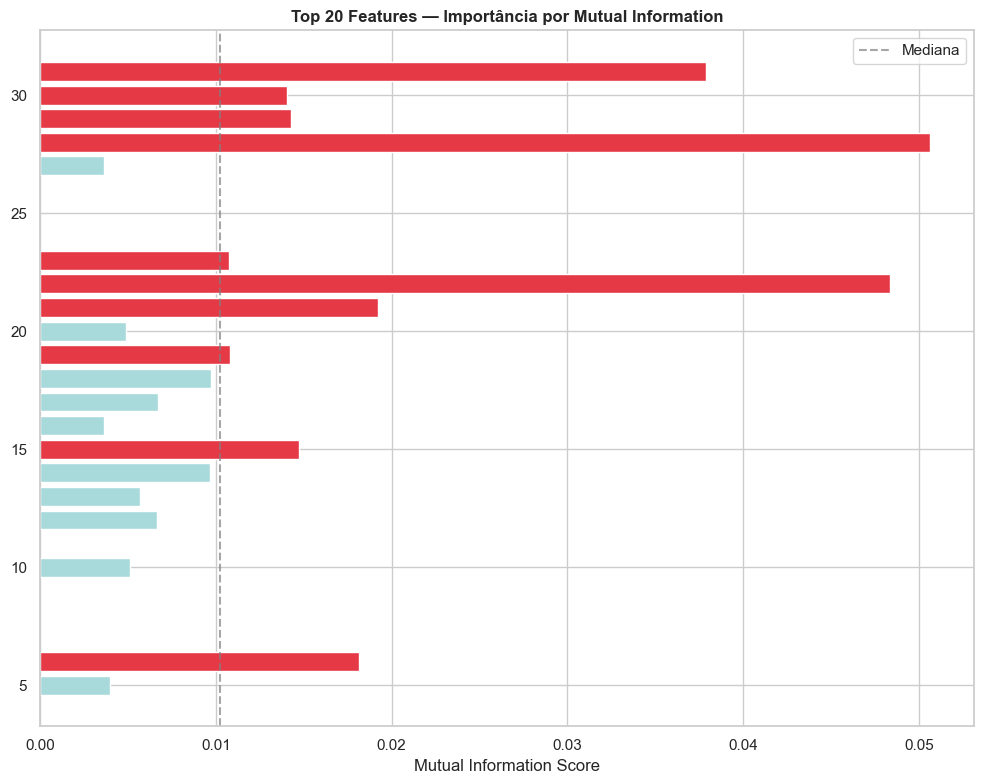

,feature,mutual_info_score
28,28,0.050606
22,22,0.048337
31,31,0.037876
21,21,0.019237
6,6,0.018120
15,15,0.014724
29,29,0.014260
30,30,0.014055
19,19,0.010816
23,23,0.010746


In [6]:
importance_df = get_feature_importance_ranking(
    pd.DataFrame(X_train_fe), y_train, n_top=20
)

plt.figure(figsize=(10, 8))
colors = ['#E63946' if v > importance_df['mutual_info_score'].median() else '#A8DADC'
          for v in importance_df['mutual_info_score']]
plt.barh(importance_df['feature'], importance_df['mutual_info_score'],
         color=colors, edgecolor='white')
plt.xlabel('Mutual Information Score')
plt.title('Top 20 Features — Importância por Mutual Information', fontweight='bold')
plt.axvline(importance_df['mutual_info_score'].median(),
            color='gray', linestyle='--', alpha=0.7, label='Mediana')
plt.legend()
plt.tight_layout()
plt.show()

importance_df

## 5. Conclusões

### ✅ Features mais relevantes identificadas:
- `contract_risk` — tipo de contrato é o preditor mais forte
- `tenure` e `tenure_squared` — tempo de relacionamento com a empresa
- `monthly_charges` e `total_charges` — valor pago mensalmente
- `internet_risk` — tipo de serviço de internet
- `payment_risk` — método de pagamento

### ➡️ Próximos passos:
- Notebook 03: Treinar modelos baseline com estas features
- Comparar performance com e sem SMOTE